In [18]:
import os
from langchain_core.documents import Document
from langchain_openai import OpenAIEmbeddings, ChatOpenAI
from langchain_community.vectorstores import FAISS
from langchain_community.retrievers import WikipediaRetriever
from langchain_classic.retrievers.multi_query import MultiQueryRetriever
from langchain_classic.retrievers import ContextualCompressionRetriever
from langchain_classic.retrievers.document_compressors import LLMChainExtractor
from dotenv import load_dotenv

load_dotenv()

True

## TABLE OF CONTENTS 

1) Vector Store 
2) MMR 
3) MultiQuery 
4) Contexual Compression 
5)  Wikipedia Retriever {giving error }

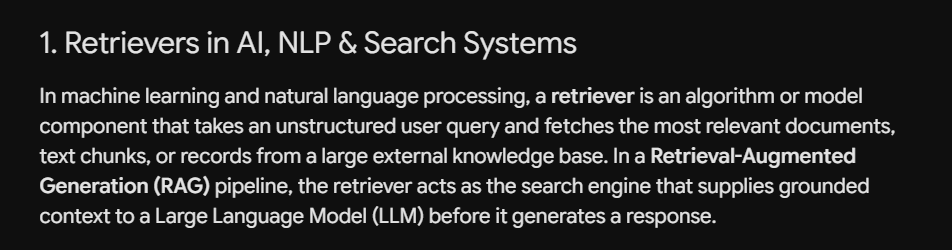
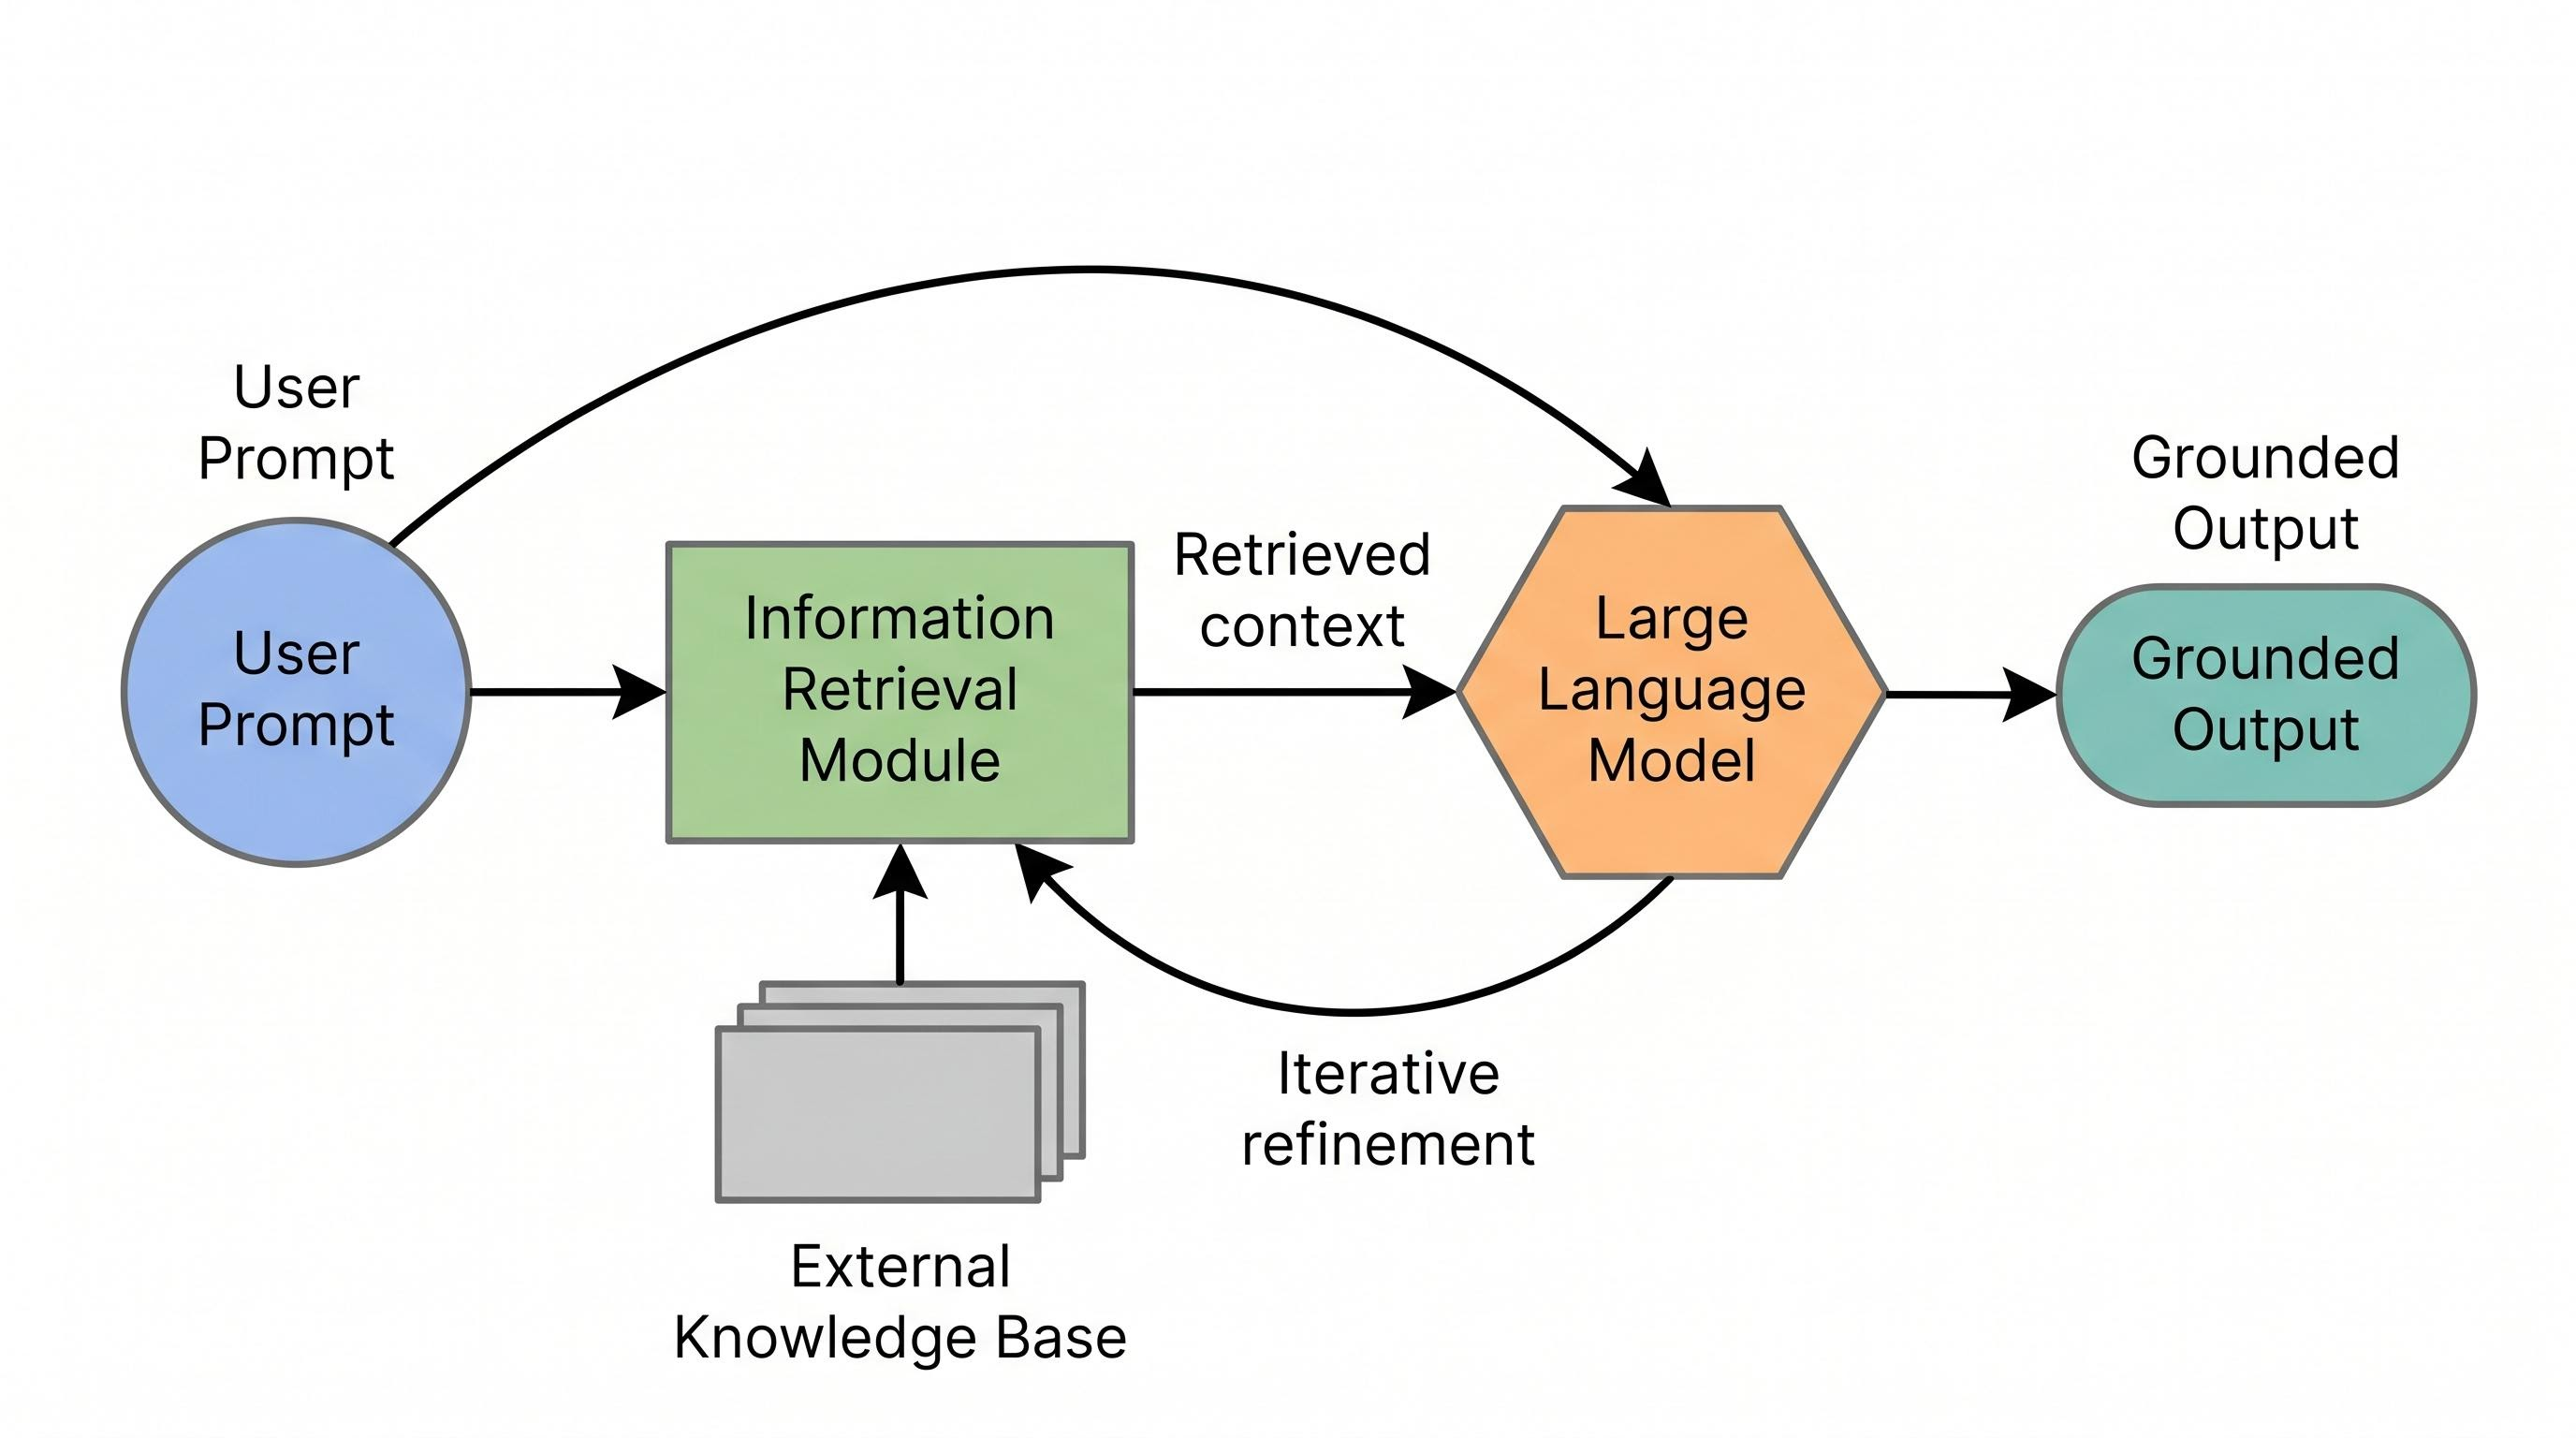

In [6]:
embedding_model = OpenAIEmbeddings()
llm = ChatOpenAI()

# sample data 
sample_docs = [
    Document(
        page_content=(
            "Regular weightlifting increases bone density and builds lean skeletal muscle. "
            "Unrelated note: The cafeteria serves masala chai at 4 PM on Tuesdays."
        ),
        metadata={"topic": "fitness", "id": 1}
    ),
    Document(
        page_content=(
            "Resistance training and lifting weights strengthen bones and promote muscle hypertrophy."
        ),
        metadata={"topic": "fitness", "id": 2}
    ),
    Document(
        page_content=(
            "Progressive overload—gradually increasing weight, volume, or intensity—is the primary "
            "driver of long-term strength adaptations."
        ),
        metadata={"topic": "fitness", "id": 3}
    ),
    Document(
        page_content=(
            "Adequate sleep (7-9 hours) and protein intake (1.6-2.2g per kg of bodyweight) are "
            "critical for recovery and central nervous system repair after heavy training."
        ),
        metadata={"topic": "recovery", "id": 4}
    ),
    Document(
        page_content=(
            "Slope deflection is a structural analysis method used to analyze indeterminate beams and frames."
        ),
        metadata={"topic": "engineering", "id": 5}
    ),
]

# Build an in-memory FAISS vector store
vectorstore = FAISS.from_documents(documents=sample_docs, embedding=embedding_model)

## 1) Vector Store Retriever 
Wraps any vector database (FAISS, Chroma, Pinecone, Qdrant) into a standard BaseRetriever. By default, it performs top-$k$ cosine/inner-product similarity search.

In [13]:
similarity_retriver =  vectorstore.as_retriever(
    search_type="similarity",
    search_kwargs={"k":2}
    
)
query =  "how much sleep is good ?"
docs =  similarity_retriver.invoke(query)

for i in docs:
    print(i.page_content)

Adequate sleep (7-9 hours) and protein intake (1.6-2.2g per kg of bodyweight) are critical for recovery and central nervous system repair after heavy training.
Regular weightlifting increases bone density and builds lean skeletal muscle. Unrelated note: The cafeteria serves masala chai at 4 PM on Tuesdays.


## 2)  Maximum Marginal Relevance (MMR) Retriever

Prevents redundant chunks by balancing query relevance against inter-document diversity:$$\text{MMR} = \arg\max_{D_i \in R \setminus S} \left[ \lambda \cdot \text{Sim}_1(D_i, Q) - (1 - \lambda) \max_{D_j \in S} \text{Sim}_2(D_i, D_j) \right]$$

In [16]:
mmr_retriever =  vectorstore.as_retriever(
    search_type="mmr",
    search_kwargs={"k":2}
    
)
query =  "how much sleep is good ?"
docs =  mmr_retriever.invoke(query)

for i in docs:
    print(i.page_content)

Adequate sleep (7-9 hours) and protein intake (1.6-2.2g per kg of bodyweight) are critical for recovery and central nervous system repair after heavy training.
Slope deflection is a structural analysis method used to analyze indeterminate beams and frames.


## 3) Multi Query Retriever 
Overcomes poorly phrased or narrow user queries by prompting an LLM to generate multiple diverse search queries from different perspectives, running retrieval on all of them, and returning the unique union of all fetched documents

In [17]:
multiquery =  MultiQueryRetriever.from_llm(
    retriever=vectorstore.as_retriever(search_kwargs={"k":2}),
    llm=llm,
    include_original=True

)

query =  "how much sleep is good ?"
docs =  multiquery.invoke(query)

for i in docs:
    print(i.page_content)

Adequate sleep (7-9 hours) and protein intake (1.6-2.2g per kg of bodyweight) are critical for recovery and central nervous system repair after heavy training.
Regular weightlifting increases bone density and builds lean skeletal muscle. Unrelated note: The cafeteria serves masala chai at 4 PM on Tuesdays.
Progressive overload—gradually increasing weight, volume, or intensity—is the primary driver of long-term strength adaptations.


## 4) Contexual Compression Retriever 
A search tool that takes bulky documents found by a search engine, reads through them, and deletes all the unhelpful filler text so that only the exact sentences answering your question are passed on to the AI.

In [21]:
base_retriever =  vectorstore.as_retriever(search_kwargs={"k":2})
compressor =  LLMChainExtractor.from_llm(llm)

contextual_retriever =  ContextualCompressionRetriever(
    base_retriever=base_retriever,
    base_compressor=compressor
)


query =  "how much sleep is good ?"
docs =  contextual_retriever.invoke(query)

for i in docs:
    print(i.page_content)

Adequate sleep (7-9 hours)
